In [20]:
import numpy as np
import pandas as pd
import scipy
import math
from matplotlib import pyplot
import seaborn as sns

In [9]:
# Make sure .svg files are saved properly from jupyter notebook
pyplot.rc("axes.spines", top=False, right=False)
pyplot.rcParams["svg.fonttype"] = "none"

In [10]:
# Get x y coordinates of points on rwz boundary.
summary = {'angle': [], 'distance': [], 'x': [], 'y': []}
border_ang = [60, 90]
ang_gradiant = [60, 65, 70, 75, 80, 85, 90]
border_dist = [8, 14]
dist_gradiant = [8, 9, 10, 11, 12, 13, 14]
for ang in ang_gradiant:
    if ang in border_ang:
        for dist in dist_gradiant:
            x = round(math.cos(np.deg2rad(ang)) * dist, 2)
            y = round(math.sin(np.deg2rad(ang)) * dist, 2)
            summary['angle'].append(ang)
            summary['distance'].append(dist)
            summary['x'].append(x)
            summary['y'].append(y)
    else:
        for dist in border_dist:
            x = round(math.cos(np.deg2rad(ang)) * dist, 2)
            y = round(math.sin(np.deg2rad(ang)) * dist, 2)
            summary['angle'].append(ang)
            summary['distance'].append(dist)
            summary['x'].append(x)
            summary['y'].append(y)
rwz_cor = pd.DataFrame(summary)



In [11]:
# Upload output file from Extract sub-movement.ipynb.
file_path = '/Volumes/sbms/groups/INCR-DuguidLab/sensorimotor control in RTT/FP/bh_sum/mov_component_kinematics.csv'
df = pd.read_csv(file_path)
df = df.drop(df.columns[0],axis=1)
df['id'] = df['id'].astype(str)
df['MI'] = df['MI'].astype(int)
df['session'] = df['session'].astype(int)
df['component_number'] = df['component_number'].astype(int)

# 
df = df[(df['component_number'] <= 10) & (df['component_number'] >= 1)]
df['distance'] = np.sqrt(df['ep_x'] ** 2 + df['ep_y'] ** 2)


In [12]:
# Get trials from early and late stages.
stage_df = df[df['session'].isin([1,2,3,18,19,20])].copy()
stage_df.loc[stage_df['session'].isin([1,2,3]), 'stage'] = 'early'
stage_df.loc[stage_df['session'].isin([18,19,20]), 'stage'] = 'late'

# Calculate distance and angle relative to center.
stage_df['distance'] = np.sqrt(stage_df['ep_x'] ** 2 + stage_df['ep_y'] ** 2)
stage_df['angle'] = np.degrees(np.arctan2(stage_df['ep_y'], stage_df['ep_x'])) % 360

# Calculate sub-movement end point angle relative to its start point.
stage_df['comp_angle'] = np.degrees(np.arctan2(stage_df['ep_y'] - stage_df['sp_y'], stage_df['ep_x'] - stage_df['sp_x'])) % 360

# Create 'target_entry' column to record if a sub-movement has entered the reward zone.
stage_df['target_entry'] = np.zeros(len(stage_df))
stage_df.loc[(stage_df['distance']>= 8) & (stage_df['distance']<= 14) & (stage_df['angle']<= 90) &  
                                            (stage_df['angle']>= 60 ),'target_entry'] = 1

# 'max_comp_in' record the maximum number of sub-movement of each trial.
stage_df['max_comp_no'] = stage_df.groupby(['id', 'stage', 'MI'])['component_number'].transform('max')

# 'first_comp_in' record if a trial's first sub-movement has entered the rwz or not. The ones ended in the rwz will be excluded later.
stage_df['first_comp_in'] = (stage_df['target_entry'].where(stage_df['component_number'] == 1)
    .groupby([stage_df['id'], stage_df['stage'], stage_df['MI']]).transform('first'))

In [13]:
# Calculate angular difference of each sub-movement to rwz.
stage_df = stage_df.reset_index(drop = True)
for idx in range(len(stage_df)):
    row = stage_df.iloc[idx]
    if row['target_entry'] == 1: # error_angle = 0 if sub_movement is in rwz.
        stage_df.loc[idx, 'error_angle'] = 0
    else:
        # Calculate the angular range in which the sub-movement is towards the rwz.
        sp_to_rwz_angle_range = np.degrees(np.arctan2(rwz_cor['y'] - row['sp_y'], rwz_cor['x'] - row['sp_x'])) % 360
        min_angle = sp_to_rwz_angle_range.min()
        max_angle = sp_to_rwz_angle_range.max()
        if row['comp_angle'] <= max_angle and row['comp_angle'] >= min_angle: # No angular error if sub-movement direction is in the range.
            stage_df.loc[idx, 'error_angle'] = 0
        else:
            ang_list = []
            for i in range(len(rwz_cor)):
                rwz_cor_row = rwz_cor.iloc[i]
                # calculate angle from sub-movement start to points on rwz boundary
                sp_to_rwz_point_ang = np.degrees(np.arctan2(rwz_cor_row['y'] - row['sp_y'], rwz_cor_row['x'] - row['sp_x'])) % 360
                # get the difference between two angles (https://towardsdatascience.com/find-the-difference-between-two-angles-using-python-ac553a1ef5c0/)
                bigger_angle = max(sp_to_rwz_point_ang, row['comp_angle'])
                smaller_angle = min(sp_to_rwz_point_ang, row['comp_angle'])
                if bigger_angle - smaller_angle > 180:
                    delta_ang = 360 - bigger_angle + smaller_angle
                else:
                    delta_ang = bigger_angle - smaller_angle
                ang_list.append(delta_ang)
            stage_df.loc[idx, 'error_angle'] = np.array(ang_list).min()    

In [14]:
# Calculate distance to rwz for each sub-movement.
for idx in range(len(stage_df)):
    row = stage_df.iloc[idx]
    if row['target_entry'] == 1:
        stage_df.loc[idx, 'dist_to_rwz'] = 0
    else:
        min_dist = np.sqrt((row['ep_x'] - rwz_cor['x']) ** 2 + (row['ep_y'] - rwz_cor['y']) ** 2).min()
        stage_df.loc[idx, 'dist_to_rwz'] = round(min_dist, 2)
stage_df

,id,session,trial_type,MI,component_number,start,end,duration,mean_speed,max_speed,...,ep_x,ep_y,stage,angle,comp_angle,target_entry,max_comp_no,first_comp_in,error_angle,dist_to_rwz
0,3014,2,failed,59023837,1,59023893,59023949,56,28.892633,38.382847,...,-2.49,-0.20,early,184.592212,180.353673,0.0,2,0.0,93.862131,8.57
1,3014,2,failed,59023837,2,59023965,59024013,48,22.409984,28.155916,...,-1.40,-0.24,early,189.727579,2.161079,0.0,2,0.0,45.979286,8.36
2,3014,2,failed,59048833,1,59048845,59048889,44,32.781883,44.626225,...,-2.85,-0.01,early,180.201037,179.610239,0.0,10,0.0,95.231801,8.50
3,3014,2,failed,59048833,2,59048933,59048945,12,15.581478,16.223720,...,-3.50,-0.05,early,180.818455,173.990994,0.0,10,0.0,97.229244,8.78
4,3014,2,failed,59048833,3,59049053,59049105,52,21.553768,25.901569,...,-2.00,-0.06,early,181.718358,0.516164,0.0,10,0.0,44.037173,8.30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34259,9037,19,correct,39446887,1,39446887,39447059,172,62.218702,165.762260,...,5.46,7.58,late,54.234167,52.668442,0.0,3,0.0,5.454168,0.98
34260,9037,19,correct,39446887,2,39447519,39447539,20,16.543819,17.697207,...,5.41,9.34,late,59.919328,86.633539,0.0,3,0.0,0.000000,0.21
34261,9037,19,correct,39446887,3,39447567,39447587,20,16.798429,18.169842,...,5.39,10.04,late,61.770758,86.729512,1.0,3,0.0,0.000000,0.00
34262,9037,19,correct,39452131,1,39452159,39452395,236,44.769365,93.717911,...,1.91,10.00,late,79.186744,77.619243,1.0,1,1.0,0.000000,0.00


In [15]:
# Exclude trials with a hit first move and the ones only used one sub-movement.
stage_df = stage_df[(stage_df['first_comp_in'] == 0) & (stage_df['max_comp_no'] != 1) ]

In [17]:
# Calculate difference between the final sub-movement and its previous sub-movement on their distance and angle relative to rwz, and get
# the mean across trials.
summary = {'id': [], 'stage': [], 'max_comp_no': [], 'comp_no': [], 'percent_target_entry': [], 'dist_to_rwz': [], 
           'delta_dist_to_rwz': [], 'delta_target_entry': [], 'error_angle': [], 'error_angle_var': [], 'comp_angle': [], 
          'delta_error_angle': []}
for mouse_id in stage_df['id'].unique():
    for stage in ['early', 'late']:
        for max_comp in stage_df['max_comp_no'].unique():
            data = stage_df[(stage_df['id'] == mouse_id) & (stage_df['stage'] == stage) & (stage_df['max_comp_no'] == max_comp)]
            if len(data[data['component_number'] == max_comp -1]) == 0 or len(data[data['component_number'] == max_comp]) == 0:
                delta_dist_to_rwz = np.nan
                delta_target_entry = np.nan
                error_dist = np.nan
                delta_error_angle = np.nan
            else:
                delta_dist_to_rwz = data[data['component_number'] == max_comp-1]['dist_to_rwz'].values- data[data['component_number'] == max_comp]['dist_to_rwz'].values
                delta_dist_to_rwz = np.mean(delta_dist_to_rwz)
                last_comp_target_entry = round(100 * len(data[(data['component_number'] == max_comp-1) & (data['target_entry'] == 1)]) / len(
                    data[data['component_number'] == max_comp-1]), 2)
                max_comp_target_entry = round(100 * len(data[(data['component_number'] == max_comp) & (data['target_entry'] == 1)]) / len(
                    data[data['component_number'] == max_comp]), 2)
                delta_target_entry = last_comp_target_entry - max_comp_target_entry
                delta_target_entry = np.mean(delta_target_entry)
                last_comp_error_angle = data[data['component_number'] == max_comp-1]['error_angle'].values
                max_comp_error_angle = data[data['component_number'] == max_comp]['error_angle'].values
                delta_error_angle = last_comp_error_angle - max_comp_error_angle
                delta_error_angle_mean = np.rad2deg(scipy.stats.circmean(np.deg2rad(delta_error_angle), high = math.pi, low = -math.pi))
            for comp_no in data['component_number'].unique():
                comp_data = data[data['component_number'] == comp_no]
                percent_target_entry = round(100 * len(comp_data[comp_data['target_entry'] == 1]) / len(comp_data) , 2)
                distance_to_target = np.median(comp_data['dist_to_rwz'])
                summary['id'].append(mouse_id)
                summary['stage'].append(stage)
                summary['max_comp_no'].append(max_comp)
                summary['comp_no'].append(comp_no)
                summary['percent_target_entry'].append(percent_target_entry)
                summary['dist_to_rwz'].append(distance_to_target)
                summary['delta_dist_to_rwz'].append(delta_dist_to_rwz)
                summary['delta_target_entry'].append(delta_target_entry)
                summary['error_angle'].append(np.rad2deg(scipy.stats.circmean(np.deg2rad(comp_data['error_angle']))))
                summary['error_angle_var'].append(np.rad2deg(scipy.stats.circstd(np.deg2rad(comp_data['error_angle']))))
                summary['comp_angle'].append(np.rad2deg(scipy.stats.circmean(np.deg2rad(comp_data['comp_angle']))))
                summary['delta_error_angle'].append(delta_error_angle_mean)
summary = pd.DataFrame(summary)
summary

,id,stage,max_comp_no,comp_no,percent_target_entry,dist_to_rwz,delta_dist_to_rwz,delta_target_entry,error_angle,error_angle_var,comp_angle,delta_error_angle
0,3014,early,2,1,0.00,5.28,0.559231,-53.85,41.305286,42.711555,116.855122,19.950097
1,3014,early,2,2,53.85,0.00,0.559231,-53.85,17.708580,35.391456,45.290558,19.950097
2,3014,early,10,1,0.00,7.34,0.096471,0.00,39.598991,38.291368,107.373665,-25.483422
3,3014,early,10,2,17.65,5.51,0.096471,0.00,23.064168,40.683295,110.342790,-25.483422
4,3014,early,10,3,5.88,6.62,0.096471,0.00,26.984913,38.199280,341.400709,-25.483422
...,...,...,...,...,...,...,...,...,...,...,...,...
1864,9037,late,8,4,33.33,0.43,0.170000,-33.33,0.000000,0.000000,113.220738,0.000000
1865,9037,late,8,5,0.00,0.20,0.170000,-33.33,0.000000,0.000000,312.832818,0.000000
1866,9037,late,8,6,33.33,0.21,0.170000,-33.33,0.000000,0.000000,267.707732,0.000000
1867,9037,late,8,7,66.67,0.00,0.170000,-33.33,0.000000,0.000000,348.765122,0.000000


In [24]:
# Get distance and angle to rwz data for trials with different number of sub-movement.
delta_df = summary.groupby(['id', 'stage', 'max_comp_no'], as_index = False)[['delta_dist_to_rwz', 'delta_error_angle']].first()


(array([-3., -2., -1.,  0.,  1.,  2.,  3.,  4.]),
 [Text(0, -3.0, '−3'),
  Text(0, -2.0, '−2'),
  Text(0, -1.0, '−1'),
  Text(0, 0.0, '0'),
  Text(0, 1.0, '1'),
  Text(0, 2.0, '2'),
  Text(0, 3.0, '3'),
  Text(0, 4.0, '4')])

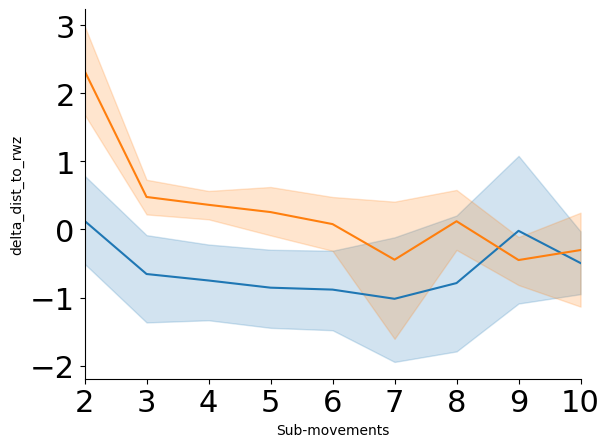

In [28]:
%matplotlib inline

pyplot.figure()
sns.lineplot(data = delta_df, x = 'max_comp_no', y = 'delta_dist_to_rwz', hue = 'stage', n_boot = 10000, legend = False)
pyplot.xlim(2, 10)
pyplot.xlabel('Sub-movements')
pyplot.xticks(fontsize = 22)
pyplot.yticks(fontsize = 22)
